#### Import Libraries

In [1]:
import pandas as pd
import numpy as np
 
from sklearn.model_selection import train_test_split
 
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
 
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
 
print("Libraries imported successfully")

Libraries imported successfully


In [2]:
data_path = r"C:\Users\10163815\PycharmProjects\industrial-predictive-maintenance\data\raw\ai4i2020.csv"
df = pd.read_csv(data_path)
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


#### Selecting features and target

In [3]:
drop_columns = [
    "UDI",
    "Product ID",
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]
 
X = df.drop(columns=drop_columns)
y = df["Machine failure"]
 
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
 
print("\nFeatures:")
print(X.columns.tolist())
 
print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (10000, 6)
Target shape: (10000,)

Features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


#### Train Test Split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
 
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
 
print("\nTraining target distribution:")
print(y_train.value_counts())
 
print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (8000, 6)
Testing features: (2000, 6)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


Why stratification

Machine failures are rare compared with normal machine operations. Stratification ensures both datasets retain approximately the same failure proportion.

#### Identifying categorical and numerical features

In [5]:
categorical_features = ["Type"]
 
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]
 
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Type']
Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


#### Creating preprocessing pipeline

In [6]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
 
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
 
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)
 
print("Preprocessing pipeline created successfully")
 

Preprocessing pipeline created successfully


Why do we need this?
1. StandardScaler brings numerical features onto comparable scales.
2. OneHotEncoder converts machine type into numerical columns.
3. SimpleImputer handles missing values if encountered.
4. Pipeline ensures transformations are learned from training data rather than the test data.

#### Validating preprocessing

In [7]:
X_train_processed = preprocessor.fit_transform(X_train)
 
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)
 
print("Preprocessing validation successful")

Original training shape: (8000, 6)
Processed training shape: (8000, 8)
Preprocessing validation successful


### Machine Learning Model Development

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
 
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
 
from sklearn.pipeline import Pipeline
 
import matplotlib.pyplot as plt
import seaborn as sns
 
print("Model development libraries imported successfully")

Model development libraries imported successfully


#### Defining 3 models
As this is a classification problem, I will be using below mentioned models

1. Logistic Regression: Baseline classification model.
2. Decision Tree: Learns nonlinear decision rules.
3. Random Forest: Combines multiple decision trees to improve generalisation.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),
 
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),
 
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}
 
print("Three candidate models defined successfully")
 

Three candidate models defined successfully


#### Creating ML Pipelines

Each model will have its own preprocessing pipeline. This ensures the transformations are fitted only on training data.

In [10]:
model_pipelines = {}
 
for model_name, model in models.items():
 
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])
 
    model_pipelines[model_name] = pipeline
 
print("All model pipelines created successfully")

All model pipelines created successfully


#### Training all three models

In [11]:
for model_name, pipeline in model_pipelines.items():
 
    print(f"Training {model_name}...")
 
    pipeline.fit(X_train, y_train)
 
    print(f"{model_name} training completed\n")

Training Logistic Regression...
Logistic Regression training completed

Training Decision Tree...
Decision Tree training completed

Training Random Forest...
Random Forest training completed



#### Evaluating model performance

In [12]:
results = []

for model_name, pipeline in model_pipelines.items():
 
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]
 
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "PR AUC": average_precision_score(y_test, y_prob)
    })
 
results_df = pd.DataFrame(results)
 
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

results_df.round(4)
 

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
2,Random Forest,0.9820,0.8200,0.6029,0.6949,0.9651,0.7618
1,Decision Tree,0.9300,0.3125,0.8824,0.4615,0.9108,0.5722
0,Logistic Regression,0.8245,0.1418,0.8235,0.2419,0.9070,0.3818


#### Detailed Classification Report

In [13]:
for model_name, pipeline in model_pipelines.items():
 
    print("=" * 60)
    print(model_name)
    print("=" * 60)
 
    y_pred = pipeline.predict(X_test)
 
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Failure", "Failure"],
        zero_division=0
    ))

Logistic Regression
              precision    recall  f1-score   support

  No Failure       0.99      0.82      0.90      1932
     Failure       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000

Decision Tree
              precision    recall  f1-score   support

  No Failure       1.00      0.93      0.96      1932
     Failure       0.31      0.88      0.46        68

    accuracy                           0.93      2000
   macro avg       0.65      0.91      0.71      2000
weighted avg       0.97      0.93      0.95      2000

Random Forest
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1932
     Failure       0.82      0.60      0.69        68

    accuracy                           0.98      2000
   macro avg       0.90      0.80      0.84      2000
weighted avg       0.98   

#### Confusion Matrices

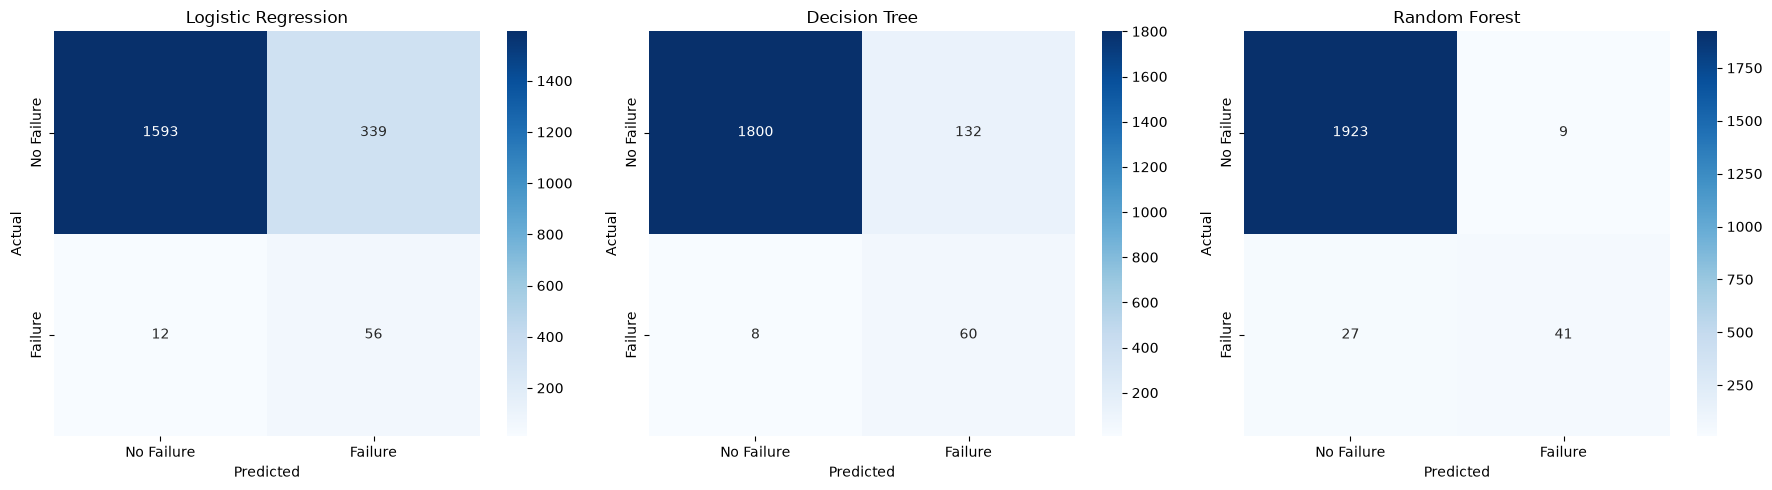

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
 
for ax, (model_name, pipeline) in zip(
    axes,
    model_pipelines.items()
):
 
    y_pred = pipeline.predict(X_test)
 
    cm = confusion_matrix(y_test, y_pred)
 
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Failure", "Failure"],
        yticklabels=["No Failure", "Failure"],
        ax=ax
    )
 
    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
 
plt.tight_layout()
plt.show()

#### Model Comparison results

In [15]:
import os
 
os.makedirs("reports", exist_ok=True)
 
results_df.to_csv(
    "reports/model_comparison.csv",
    index=False
)
 
print("Model comparison saved successfully")

Model comparison saved successfully


### Model Selection and Cross Validation

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
 
print("Cross-validation libraries imported successfully")

Cross-validation libraries imported successfully


#### performing 5 fold cross validation

In [17]:
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}
 
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
 
cv_results = []
 
for model_name, pipeline in model_pipelines.items():
 
    print(f"Evaluating {model_name}...")
 
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
 
    cv_results.append({
        "Model": model_name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC AUC": scores["test_roc_auc"].mean(),
        "PR AUC": scores["test_average_precision"].mean()
    })
 
cv_results_df = pd.DataFrame(cv_results)
 
cv_results_df.round(4)

Evaluating Logistic Regression...
Evaluating Decision Tree...
Evaluating Random Forest...


,Model,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,Logistic Regression,0.1374,0.8044,0.2346,0.8965,0.4409
1,Decision Tree,0.3063,0.8894,0.4553,0.9014,0.5586
2,Random Forest,0.8108,0.5094,0.6245,0.9708,0.7424


#### Comparing Cross Vlidation

In [18]:
cv_results_df.sort_values(
    by=["F1 Score", "PR AUC"],
    ascending=False
)

,Model,Precision,Recall,F1 Score,ROC AUC,PR AUC
2,Random Forest,0.810832,0.509360,0.624549,0.970789,0.742423
1,Decision Tree,0.306292,0.889360,0.455287,0.901395,0.558555
0,Logistic Regression,0.137368,0.804444,0.234570,0.896525,0.440897


Do not automatically select the model with the highest F1-score.
For industrial predictive maintenance, we must consider the cost of missed failures and unnecessary maintenance alerts.

#### Visualizing model comparison

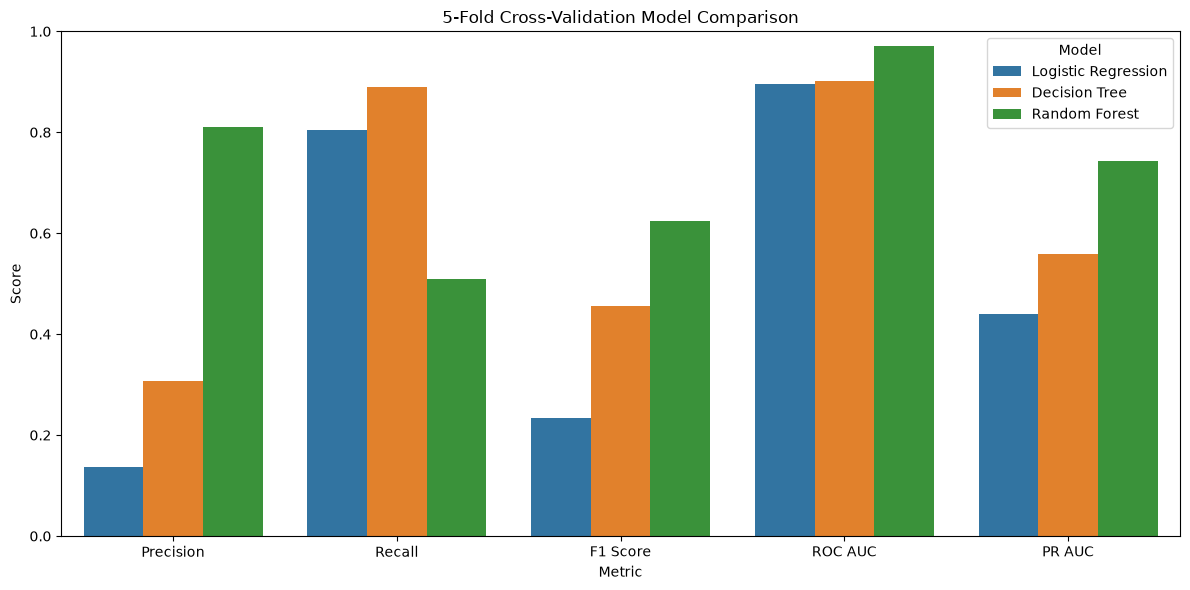

In [19]:
cv_melted = cv_results_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)
 
plt.figure(figsize=(12, 6))
 
sns.barplot(
    data=cv_melted,
    x="Metric",
    y="Score",
    hue="Model"
)
 
plt.title("5-Fold Cross-Validation Model Comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

#### Saving Cross Validation Results

In [20]:
cv_results_df.to_csv(
    "reports/cross_validation_results.csv",
    index=False
)
 
print("Cross-validation results saved successfully")

Cross-validation results saved successfully


### Model Selection and Decision Threshold Optimisation

#### Rank and select the best model

In [21]:
cv_ranked = cv_results_df.sort_values(
    by=["F1 Score", "PR AUC"],
    ascending=False
)
 
display(cv_ranked.round(4))

,Model,Precision,Recall,F1 Score,ROC AUC,PR AUC
2,Random Forest,0.8108,0.5094,0.6245,0.9708,0.7424
1,Decision Tree,0.3063,0.8894,0.4553,0.9014,0.5586
0,Logistic Regression,0.1374,0.8044,0.2346,0.8965,0.4409


#### Selecting top-performing model

In [22]:
best_model_name = cv_ranked.iloc[0]["Model"]
 
best_pipeline = model_pipelines[best_model_name]
 
print("Selected Model:", best_model_name)

Selected Model: Random Forest


#### Creating Validation Dataset

In [23]:
from sklearn.model_selection import train_test_split
 
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)
 
print("Sub-training shape:", X_subtrain.shape)
print("Validation shape:", X_val.shape)
 
print("\nValidation target distribution:")
print(y_val.value_counts())

Sub-training shape: (6400, 6)
Validation shape: (1600, 6)

Validation target distribution:
Machine failure
0    1546
1      54
Name: count, dtype: int64


#### Train the selected model

In [24]:
best_pipeline.fit(X_subtrain, y_subtrain)
 
print(f"{best_model_name} trained successfully.")

Random Forest trained successfully.


Why are we training again?

The model selected through cross-validation needs to be fitted on the sub-training data before it can generate validation predictions.

Remember that the pipeline contains:
1. Missing-value imputation.
2. Numerical feature scaling.
3. Categorical feature encoding.
4. Classification algorithm.

The preprocessing steps are fitted only on the sub-training data.

#### Generate failure probablities

In [25]:
y_val_prob = best_pipeline.predict_proba(X_val)[:, 1]
 
print("First 10 predicted probabilities:")
print(y_val_prob[:10])

First 10 predicted probabilities:
[0.         0.0984911  0.00947408 0.06703851 0.0063098  0.74073919
 0.02560389 0.         0.00321354 0.        ]


#### Optimise the decision threshold

By default binary classification generally uses a threshold of 0.5

In [26]:
from sklearn.metrics import precision_recall_curve
import numpy as np
 
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_prob
)
 
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)
 
best_threshold_index = np.argmax(f1_scores)
 
best_threshold = thresholds[best_threshold_index]
 
print("Best Threshold:", round(best_threshold, 4))
print("Precision:", round(precision[best_threshold_index], 4))
print("Recall:", round(recall[best_threshold_index], 4))
print("F1 Score:", round(f1_scores[best_threshold_index], 4))
 

Best Threshold: 0.4796
Precision: 0.8158
Recall: 0.5741
F1 Score: 0.6739


#### Visualizing threshold performance

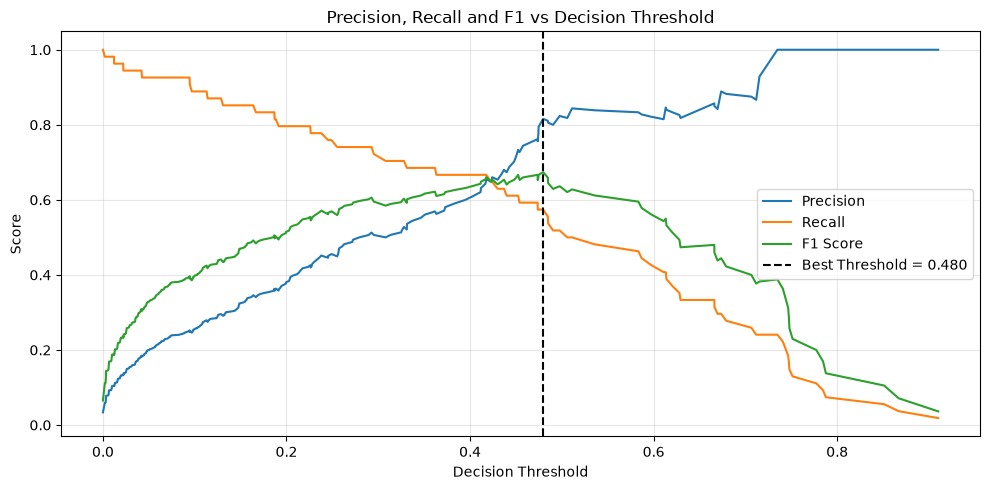

In [27]:
import matplotlib.pyplot as plt
 
plt.figure(figsize=(10, 5))
 
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")
plt.plot(thresholds, f1_scores, label="F1 Score")
 
plt.axvline(
    best_threshold,
    color="black",
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.3f}"
)
 
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Decision Threshold")
 
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Final Model Evaluation

During Phase 5, we trained the model using only X_subtrain and y_subtrain.
Now that threshold selection is complete, we can train it on the entire training dataset.


In [28]:
# Retrain selected model using the complete training dataset
 
best_pipeline.fit(X_train, y_train)
 
print(f"{best_model_name} retrained successfully.")
print("Training data shape:", X_train.shape)

Random Forest retrained successfully.
Training data shape: (8000, 6)


#### Generate predictions on the test dataset

In [29]:
# Predict failure probabilities
 
y_test_prob = best_pipeline.predict_proba(X_test)[:, 1]
 
print("First 10 predicted failure probabilities:")
print(y_test_prob[:10])

First 10 predicted failure probabilities:
[0.31336306 0.         0.09512787 0.01899853 0.11482964 0.
 0.01914962 0.         0.         0.21890328]


In [30]:
# Apply optimised decision threshold
 
y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)
 
print("Predictions generated successfully.")
print("Selected threshold:", best_threshold)

Predictions generated successfully.
Selected threshold: 0.4795900438672445


#### Calculate final evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
 
final_results = {
    "Model": best_model_name,
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test, y_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, y_test_pred, zero_division=0
    ),
    "ROC AUC": roc_auc_score(y_test, y_test_prob),
    "Average Precision": average_precision_score(
        y_test, y_test_prob
    )
}
 
final_results_df = pd.DataFrame([final_results])
 
display(final_results_df.round(4))

### Model Interpretation and feature Importance

Identify the most influential sensor features.
Understand how sensor parameters affect failure predictions.
Visualise feature importance.
Interpret individual predictions.
Document the findings for the project report.

In [34]:
print("Selected Model:", best_model_name)
print("Optimised Threshold:", best_threshold)

Selected Model: Random Forest
Optimised Threshold: 0.4795900438672445


In [35]:
from sklearn.inspection import permutation_importance
 
perm_importance = permutation_importance(
    best_pipeline,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=1
)
 
print("Permutation importance calculated successfully.")

Permutation importance calculated successfully.


#### Creating feature importance table

In [36]:
feature_importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm_importance.importances_mean,
    "Importance Std": perm_importance.importances_std
})
 
feature_importance_df = feature_importance_df.sort_values(
    by="Importance Mean",
    ascending=False
)
 
display(feature_importance_df.round(5))

,Feature,Importance Mean,Importance Std
4,Torque [Nm],0.44520,0.02709
3,Rotational speed [rpm],0.42038,0.02362
1,Air temperature [K],0.32110,0.06200
5,Tool wear [min],0.25331,0.03003
2,Process temperature [K],0.09666,0.03344
0,Type,0.04350,0.02633


#### Visualizing feature importance

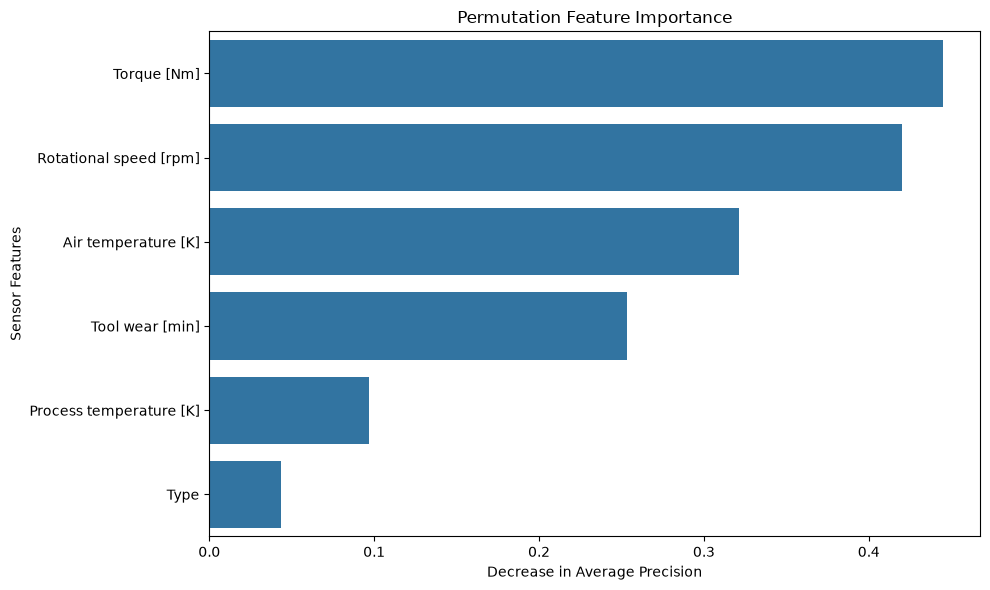

In [37]:
plt.figure(figsize=(10, 6))
 
sns.barplot(
    data=feature_importance_df,
    x="Importance Mean",
    y="Feature"
)
 
plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in Average Precision")
plt.ylabel("Sensor Features")
 
plt.tight_layout()
plt.show()

#### Analyse how sensor values differ between failure and non-failure records

In [38]:
sensor_failure_summary = X_test.copy()
 
sensor_failure_summary["Machine Failure"] = y_test.values
 
sensor_failure_summary.groupby(
    "Machine Failure"
)[[
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]].mean().T

Machine Failure,0,1
Air temperature [K],299.976812,300.742647
Process temperature [K],309.998861,310.136765
Rotational speed [rpm],1538.454969,1479.573529
Torque [Nm],39.560870,50.155882
Tool wear [min],107.455487,153.323529


#### Visualizing Sensor behaviour

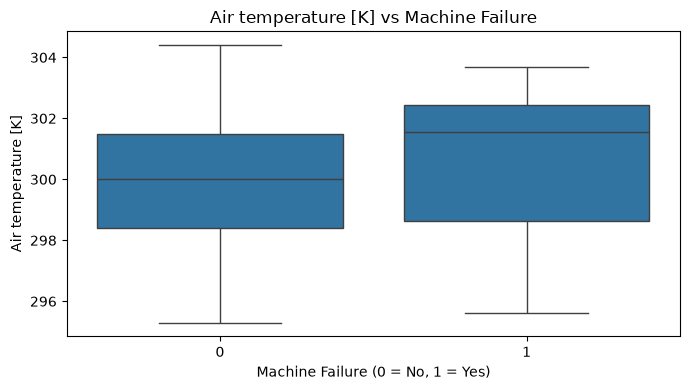

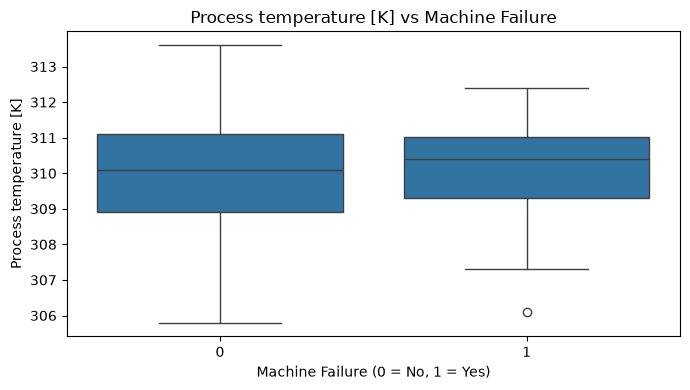

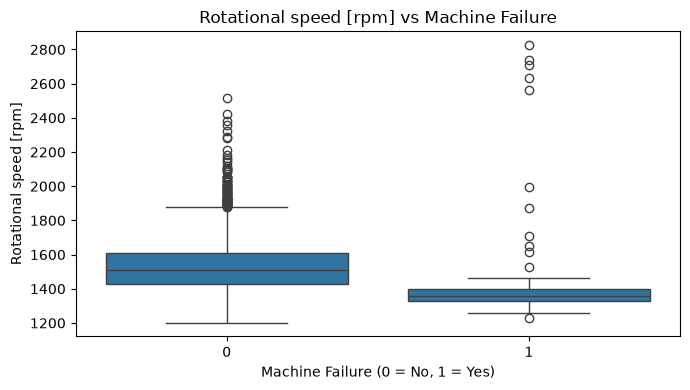

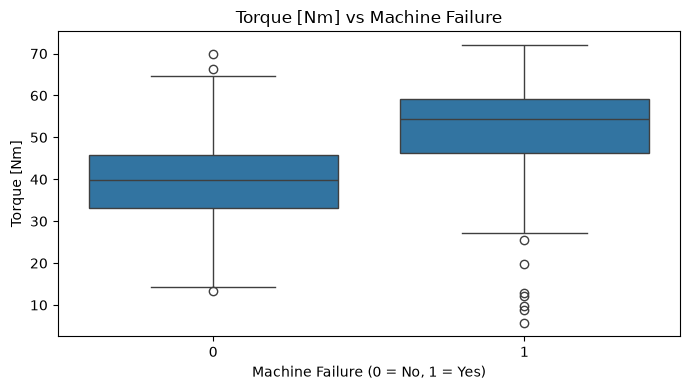

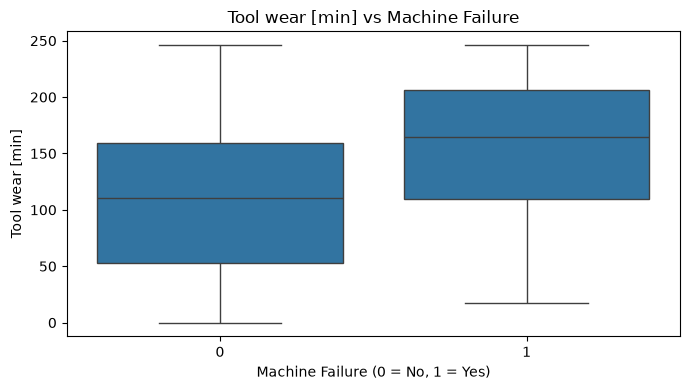

In [39]:
sensor_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
 
for column in sensor_columns:
 
    plt.figure(figsize=(7, 4))
 
    sns.boxplot(
        data=sensor_failure_summary,
        x="Machine Failure",
        y=column
    )
 
    plt.title(f"{column} vs Machine Failure")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
 
    plt.tight_layout()
    plt.show()

Summary:
1. Rotational speed is lower for failed machines
2. Torque is higher for failed machines
3. Greater tool wear for failed machines
4. No much diffrence in the temperature pattern                    
            


#### Saving the results

In [40]:
feature_importance_df.to_csv(
    "reports/feature_importance.csv",
    index=False
)
 
print("Feature importance report saved successfully.")

Feature importance report saved successfully.


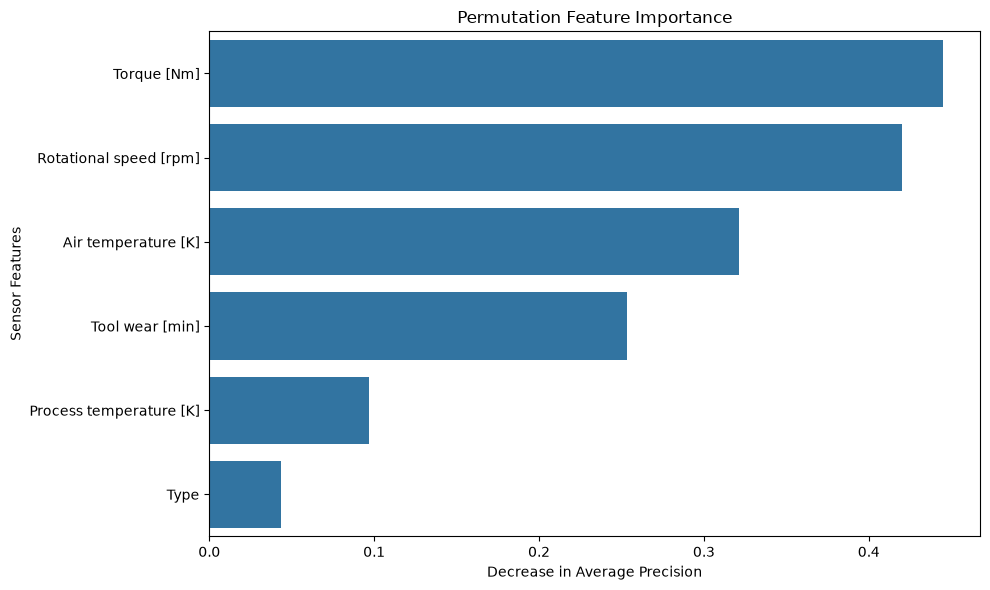

In [41]:
os.makedirs("images", exist_ok=True)
 
plt.figure(figsize=(10, 6))
 
sns.barplot(
    data=feature_importance_df,
    x="Importance Mean",
    y="Feature"
)
 
plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in Average Precision")
plt.ylabel("Sensor Features")
 
plt.tight_layout()
 
plt.savefig(
    "images/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
 
plt.show()
 

### Model Serialiation and Saving

In [42]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [43]:
import joblib
import os
import json
 
print("Joblib and required libraries imported successfully.")

Joblib and required libraries imported successfully.


In [44]:
os.makedirs("models", exist_ok=True)
 
print("Models directory is ready.")

Models directory is ready.


#### Saving the final pipeline

In [46]:
model_path = r"C:\Users\10163815\PycharmProjects\industrial-predictive-maintenance\models\predictive_maintenance_model.pkl"
 
joblib.dump(best_pipeline, model_path)
 
print("Model saved successfully!")
print("Saved location:", model_path)

Model saved successfully!
Saved location: C:\Users\10163815\PycharmProjects\industrial-predictive-maintenance\models\predictive_maintenance_model.pkl


#### Saving Optimized threshold

In [48]:
threshold_path = r"C:\Users\10163815\PycharmProjects\industrial-predictive-maintenance\models\decision_threshold.json"
 
threshold_config = {
    "selected_model": best_model_name,
    "decision_threshold": float(best_threshold),
    "target_column": "Machine failure"
}
 
with open(threshold_path, "w") as file:
    json.dump(threshold_config, file, indent=4)
 
print("Decision threshold saved successfully!")
 

Decision threshold saved successfully!


#### Reload the saved model

In [49]:
model_path = r"C:\Users\10163815\PycharmProjects\industrial-predictive-maintenance\models\predictive_maintenance_model.pkl"
loaded_model = joblib.load(
    model_path
)
 
print("Saved model loaded successfully!")
print("Loaded model:", loaded_model)

Saved model loaded successfully!
Loaded model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                

#### Verifying prediction consistency

In [50]:
original_probabilities = best_pipeline.predict_proba(X_test)[:, 1]
 
loaded_probabilities = loaded_model.predict_proba(X_test)[:, 1]
 
predictions_match = np.allclose(
    original_probabilities,
    loaded_probabilities
)
 
print("Original and loaded predictions match:", predictions_match)
 

Original and loaded predictions match: True


#### Verifying threshold Configuration

In [52]:
threshold_path = r"C:\Users\10163815\PycharmProjects\industrial-predictive-maintenance\models\decision_threshold.json"
with open(threshold_path, "r") as file:
    loaded_threshold_config = json.load(file)
 
loaded_threshold = loaded_threshold_config["decision_threshold"]
 
print("Selected model:", loaded_threshold_config["selected_model"])
print("Loaded threshold:", loaded_threshold)

Selected model: Random Forest
Loaded threshold: 0.4795900438672445


#### Generating sample prediction using saved model

In [53]:
sample_machine = pd.DataFrame([{
    "Type": "M",
    "Air temperature [K]": 300.0,
    "Process temperature [K]": 310.0,
    "Rotational speed [rpm]": 1500,
    "Torque [Nm]": 40.0,
    "Tool wear [min]": 120
}])
 
sample_probability = loaded_model.predict_proba(
    sample_machine
)[:, 1][0]
 
sample_prediction = int(
    sample_probability >= loaded_threshold
)
 
print("Failure probability:", round(sample_probability, 4))
print("Predicted failure:", sample_prediction)
 
if sample_prediction == 1:
    print("Alert: Potential machine failure detected!")
else:
    print("Status: No failure predicted.")

Failure probability: 0.0
Predicted failure: 0
Status: No failure predicted.
